## Laboratory 8 homework

Homework is creating a multimodal similarity search service. It will retrieve images
based on a text query, using embeddings from a multimodal model.

### Dataset preparation (1 point)

1. Download the dataset: [Amazon Berkeley Objects Dataset](https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-images-small.tar)
2. Unpack the dataset and locate the metadata file `images.csv.gz` in `images/metadata/`
3. Extract the image paths from the dataset:
   - write a Python script that extracts valid image paths from the CSV file
   - keep only images with at least 1000 pixels of width and height
   - you can use Pandas, Polars etc. as you wish, add with `uv` whatever is necessary

In [1]:
import os
import pandas as pd

df = pd.read_csv("data/images/metadata/images.csv.gz")
df = df[(df["width"] >= 1000) & (df["height"] >= 1000)]

image_paths = [os.path.join("data/images/small", path) for path in df["path"]]
image_paths = [path for path in image_paths if os.path.exists(path)]

len(image_paths)

342878

### Model Selection and Understanding (1 point)

1. Read the [CLIP Image Search Tutorial](https://www.sbert.net/examples/applications/image-search/README.html).
2. Search for `clip-ViT-B-32` model from `sentence-transformers` on HuggingFace Hub.
3. Determine the vector length (size) produced by the model, and what type of model is it.

**Questions:**
- What is the vector size produced by `clip-ViT-B-32`?
- What do `ViT`, `B` and `32` mean in the model name?

Odpowiedzi:
- Model zwraca wektory o długości **512**.
- Typ modelu: CLIP - model multimodalny, który zamienia obrazy i teksty na wektory w tej samej przestrzeni, więc można porównywać obraz z opisem.
- `ViT` - Vision Transformer, czyli transformer dla obrazów.
- `B` - Base, rozmiar modelu (mniejszy od `L` - Large).
- `32` - rozmiar patcha: obraz jest dzielony na kwadraty 32×32 piksele, które trafiają do transformera jak tokeny.

### Database setup (2 points)

1. Set up Postgres database with `pgvectorscale` extension. You can reuse the database from
   the lab.
2. Use SQLAlchemy to connect to it with `create_engine` and `URL`.
3. Create a database table definition for storing image embeddings. Complete the following SQLAlchemy model:

In [2]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db"
)

engine = create_engine(db_url)

In [3]:
from typing import List
from pgvector.sqlalchemy import Vector
from sqlalchemy import String
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column


class Base(DeclarativeBase):
    __abstract__ = True


class Img(Base):
    __tablename__ = "images"
    __table_args__ = {'extend_existing': True}
    
    VECTOR_LENGTH: int = 512
    
    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(256))
    embedding: Mapped[List[float]] = mapped_column(Vector(VECTOR_LENGTH))
    
# Create table
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)

### Image vectorization (3 points)

Fill the code below that performs image vectorization, i.e. calculates an embedding for each
image. Model input is an image, its output is a vector (embedding).

Notes:
1. Adjust `MAX_IMAGES`, the number of images processed, based on your computational capabilities.
   The more images you process, the more accureate results of search you will get. If you have a
   GPU, you can use it and process more images.
2. Load the CLIP model with `sentence-transformers`. It is a nice, high-level framework, based on
   PyTorch. To enable GPU usage, the following code is useful:

In [4]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

3. Implement [batching](https://docs.python.org/3/library/itertools.html#itertools.batched) for efficiency,
   as embedding a single image at a time is very inefficient. In that case, you would spend most of the time
   sending data between RAM and CPU/GPU, instead of actually doing the work. Working in batches optimizes
   this transfer time. Similarly, batching is more efficient for databases, as it lowers the overhead for
   managing transactions.
4. Implement all necessary code parts:
   - iterate through image paths
   - implement batching
   - insert batch of images into the database
   - update progress bar `pgar` with appropriate batch size

In [5]:
import joblib
from PIL import Image
from sentence_transformers import SentenceTransformer
from sqlalchemy.orm import Session
from tqdm.notebook import tqdm

MAX_IMAGES = 5000 # Adjust it for your needs
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)

model = SentenceTransformer("clip-ViT-B-32", device=device)

def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()

def vectorize_images(engine, model, image_paths):    
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in [image_paths[i:i + BATCH_SIZE] for i in range(0, MAX_IMAGES, BATCH_SIZE)]:
            images = [Image.open(path) for path in images_paths_batch]
        
            # calculate embeddings
            embeddings = model.encode(images)
        
            # create Img instances for all images in batch
            imgs = [Img(image_path=path, embedding=embedding) for path, embedding in zip(images_paths_batch, embeddings)]
        
            # insert all batch images
            insert_images(engine, imgs)
        
            # update pbar
            pbar.update(len(imgs))

vectorize_images(engine, model, image_paths)

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


  0%|          | 0/5000 [00:00<?, ?it/s]

### Search and results display (3 points)

Fill the code below that searches for the most similar embeddings based
on a text description. After that:
1. Check a few different queries. Are results relevant?
2. Check 3 different MAX_IMAGES sizes. Do you see more accurate results for larger datasets?

In [6]:
import matplotlib.pyplot as plt
from sqlalchemy import select

class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model
        
    def __call__(self, image_description: str, k: int):
        found_images = self.find_similar_images(image_description, k)
        self.display_images([img.image_path for img in found_images])

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = self.model.encode(image_description)
        
        with Session(self.engine) as session:
            query = (
                select(Img)
                .order_by(Img.embedding.cosine_distance(image_embedding))
                .limit(k)
            )
            result = session.execute(query, execution_options={"prebuffer_rows": True}).scalars().all()
        return result
    
    def display_images(self, images):
        fig, axes = plt.subplots(1, len(images), figsize=(15, 5))
        
        for i, img_path in enumerate(images):
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i+1}")
        
        plt.show()

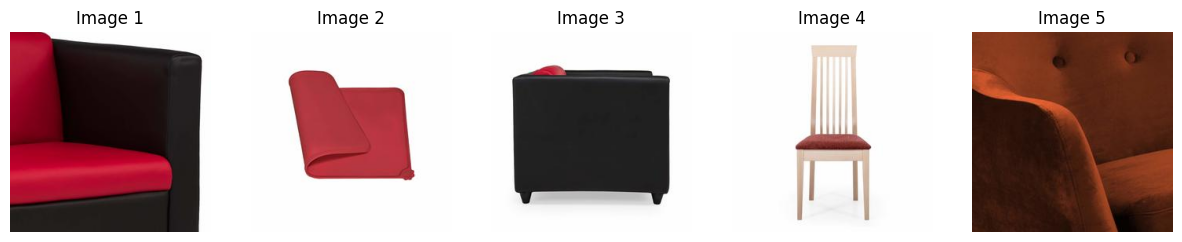

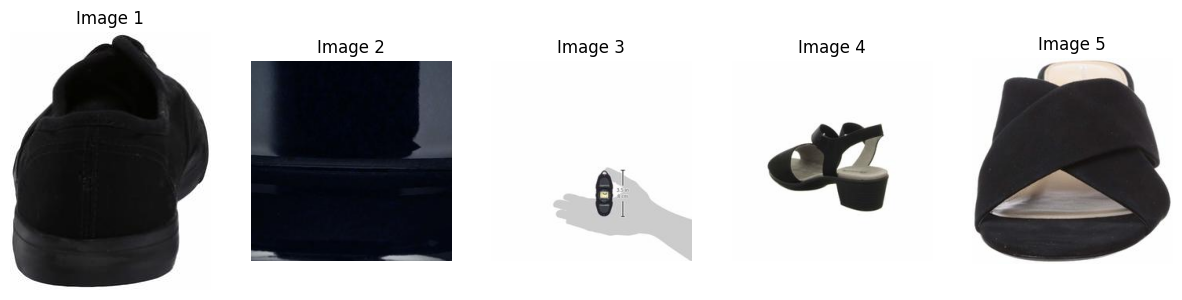

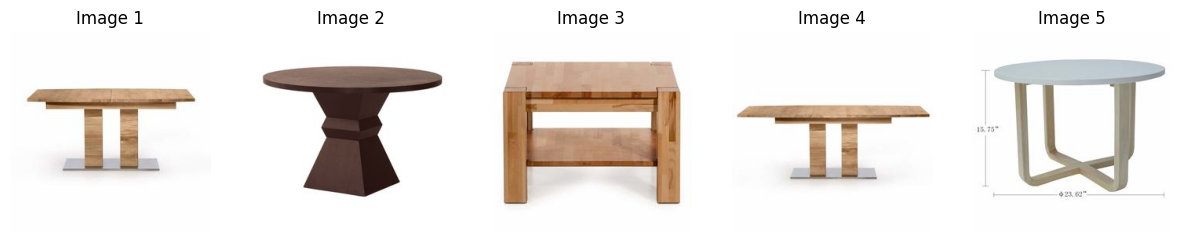

In [7]:
image_search = ImageSearch(engine, model)

image_search("red chair", 5)
image_search("black shoes", 5)
image_search("wooden table", 5)

  0%|          | 0/20000 [00:00<?, ?it/s]

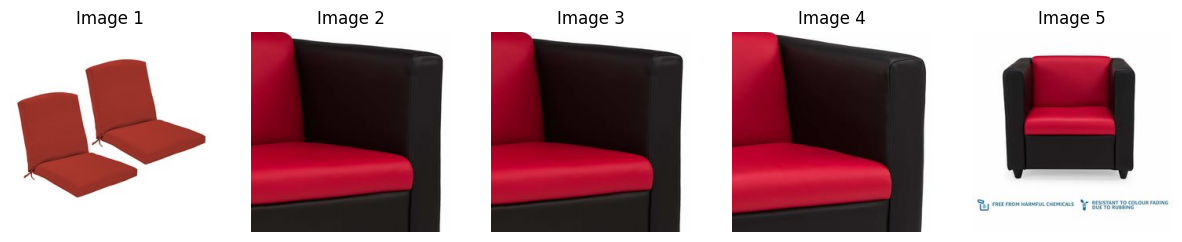

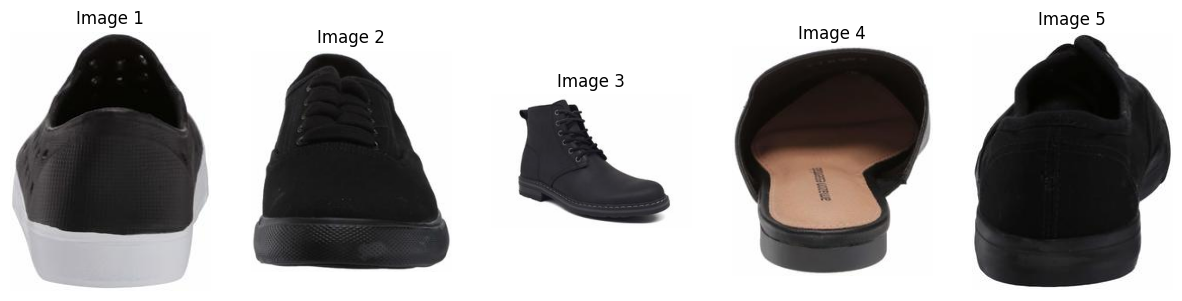

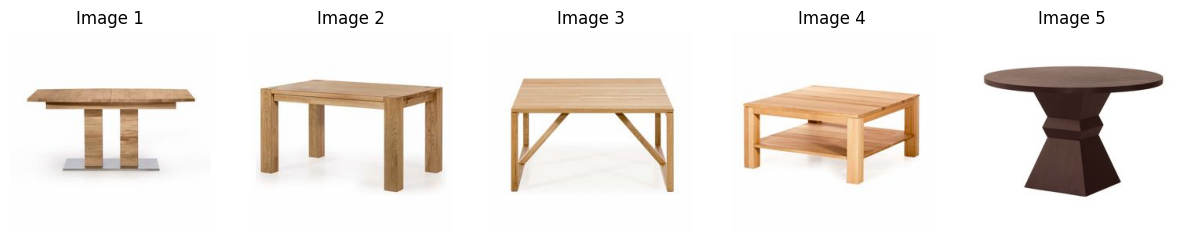

In [8]:
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)
MAX_IMAGES = 20000
vectorize_images(engine, model, image_paths)

image_search("red chair", 5)
image_search("black shoes", 5)
image_search("wooden table", 5)

  0%|          | 0/50000 [00:00<?, ?it/s]

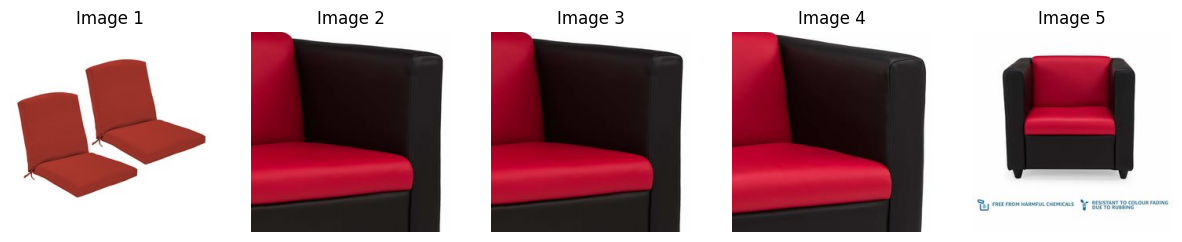

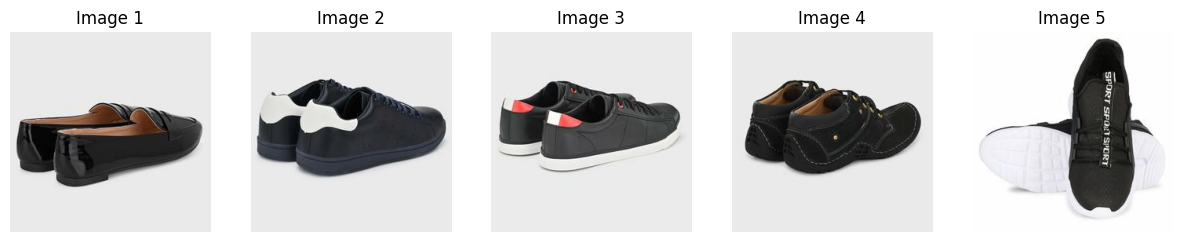

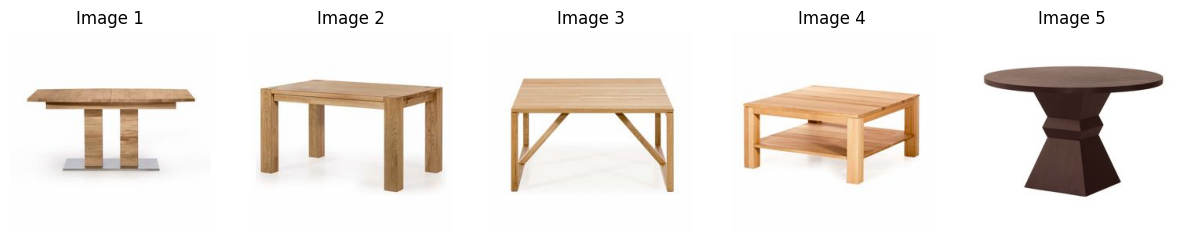

In [9]:
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)
MAX_IMAGES = 50000
vectorize_images(engine, model, image_paths)

image_search("red chair", 5)
image_search("black shoes", 5)
image_search("wooden table", 5)

Odpowiedzi:
1. Wyniki są w większości trafne - model dobiera kolor i typ przedmiotu. Przy 5000 zdjęć zdarzają się błędy (np. czerwona mata dla „red chair”, małe urządzenie dla „black shoes”).
2. Tak, przy 20000 i 50000 wyniki są trafniejsze - wszystkie buty są czarne, a stoły drewniane. Dla „red chair” i „wooden table” wyniki przy 20000 i 50000 są takie same, bo najlepsze dopasowania były już w pierwszych 20000 zdjęć. Często pojawia się kilka zdjęć tego samego produktu.